# Chapitre 11 - Cours 3 : bases de données et flux, la capture des changements (CDC)

Les courtiers à journal ont emprunté des idées aux bases de données. Ce notebook fait le
chemin inverse : appliquer aux bases de données des idées venues des flux. Le point de
départ est simple : **chaque écriture dans une base est un événement**, que l'on peut
capturer, stocker et traiter.

Il couvre le début de la section *Databases and Streams* : l'introduction, *Keeping
Systems in Sync*, *Change Data Capture* (*Implementing change data capture*, *Initial snapshot*,
*Log compaction*, *API support for change streams*). L'event sourcing et l'immutabilité
sont l'objet du cours 4.

**Plan.**

1. Le journal de réplication est déjà un flux.
2. Garder des systèmes en phase : les deux défauts de la double écriture.
3. La capture des changements (CDC), implémentée sur SQLite.
4. L'instantané initial et sa position dans le journal.
5. La compaction du journal.
6. Les interfaces de flux de changements.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Le journal de réplication est déjà un flux (section *Databases and Streams*)

Un **journal de réplication** (chapitre 5) est un flux d'événements
d'écriture produit par le leader ; les suiveurs l'appliquent à leur copie et obtiennent
les mêmes données. C'est un cas particulier du principe de **réplication de machine à
états** (state machine replication, chapitre 9) : si chaque événement est
une écriture déterministe et que toutes les répliques traitent **les mêmes événements dans
le même ordre**, elles aboutissent au même état. Vérifions-le, et voyons ce qui se passe
quand l'ordre diffère : les opérations sur une même clé ne commutent pas.

In [2]:
ops = [("x", "set", 5), ("x", "add", 3), ("y", "set", 1), ("x", "mul", 2), ("y", "add", 4), ("x", "set", 0),
       ("x", "add", 7)]

def appliquer(etat, op):
    k, f, v = op
    etat = dict(etat)
    etat[k] = {"set": v, "add": etat.get(k, 0) + v, "mul": etat.get(k, 0) * v}[f]
    return etat

def rejouer(ordre):
    e = {}
    for op in ordre:
        e = appliquer(e, op)
    return e

r1, r2 = rejouer(ops), rejouer(ops)
melange = [ops[i] for i in rng.permutation(len(ops))]
print("réplique 1 :", r1, "| réplique 2 (même ordre) :", r2)
print("réplique 3 (ordre différent) :", rejouer(melange))
etats = {}
for s in range(200):
    o = [ops[i] for i in np.random.default_rng(s).permutation(len(ops))]
    etats[str(sorted(rejouer(o).items()))] = etats.get(str(sorted(rejouer(o).items())), 0) + 1
print(f"200 ordres aléatoires donnent {len(etats)} états finaux différents")

réplique 1 : {'x': 7, 'y': 5} | réplique 2 (même ordre) : {'x': 7, 'y': 5}
réplique 3 (ordre différent) : {'y': 5, 'x': 8}
200 ordres aléatoires donnent 34 états finaux différents


Le même journal dans le même ordre donne le même état ; changer l'ordre de ces sept
opérations donne 34 états finaux différents sur 200 ordres tirés au hasard. Toute la suite du cours en
découle : pour qu'un système dérivé reste fidèle à une base, il faut lui faire appliquer
**les mêmes écritures, dans l'ordre où la base les a appliquées**.

> **À retenir.** Une base de données est un état ; son journal de réplication est le flux
> d'écritures qui produit cet état. Mêmes événements, même ordre, traitement déterministe :
> même état.

## 2. Garder des systèmes en phase (section *Keeping Systems in Sync*)

Aucun système ne satisfait seul tous les besoins de stockage, de requête et de
traitement : une application réelle combine typiquement une base transactionnelle (OLTP)
pour servir les utilisateurs, un **cache** pour accélérer les requêtes fréquentes, un
**index plein texte** pour la recherche et un **entrepôt de données** pour l'analytique.
Chacun a sa copie des données, dans sa propre représentation, et toutes doivent rester
synchronisées.

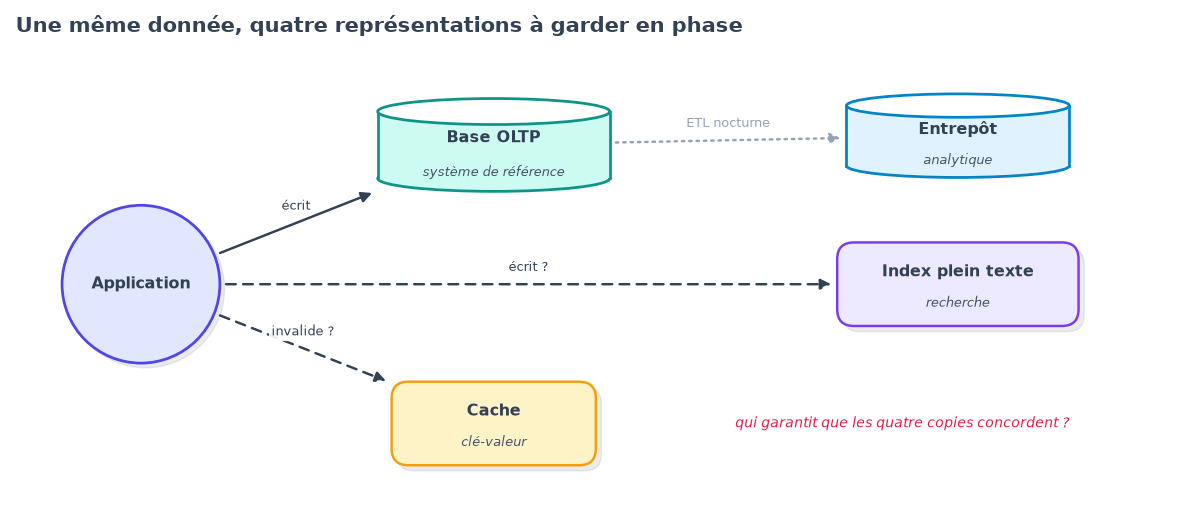

In [3]:
d = Diagram(12.5, 4.8, title="Une même donnée, quatre représentations à garder en phase")
d.box("app", 1.4, 2.4, "Application", color=INDIGO, kind="user", w=1.7)
d.box("db", 5.2, 3.9, "Base OLTP", sub="système de référence", color=TEAL, kind="db", w=2.5, h=1.0)
d.box("cache", 5.2, 0.9, "Cache", sub="clé-valeur", color=AMBER, w=2.2)
d.box("idx", 10.2, 2.4, "Index plein texte", sub="recherche", color=VIOLET, w=2.6)
d.box("dw", 10.2, 4.0, "Entrepôt", sub="analytique", color=SKY, kind="db", w=2.4, h=0.9)
d.arrow("app", "db", "écrit")
d.arrow("app", "cache", "invalide ?", style="dashed")
d.arrow("app", "idx", "écrit ?", style="dashed")
d.arrow("db", "dw", "ETL nocturne", style="dotted", color=GRAY)
d.note(9.6, 0.9, "qui garantit que les quatre copies concordent ?", color=ROSE)
d.show()

Pour l'entrepôt, on recourt classiquement à l'ETL : copie complète périodique de la base,
transformation, chargement en masse, c'est-à-dire un traitement par lots. Si c'est trop
lent, on est tenté par la **double écriture** (dual writes) : le code de l'application
écrit explicitement dans chaque système, par exemple dans la base, puis dans l'index, puis
invalide le cache. Elle a deux défauts graves.

**Défaut 1 : une course.** Deux clients mettent à jour la même donnée X, l'un à A, l'autre
à B. Chacun écrit d'abord dans la base, puis dans l'index. Les délais du réseau peuvent
entrelacer les requêtes ainsi :

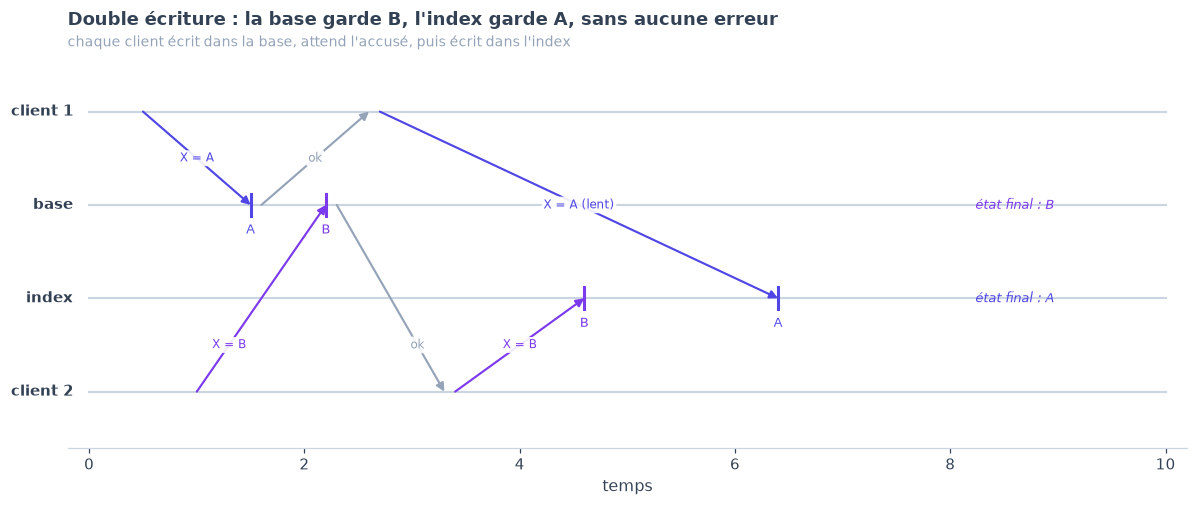

In [4]:
stt = SpaceTime(["client 1", "base", "index", "client 2"], t_max=10, width=11,
                title="Double écriture : la base garde B, l'index garde A, sans aucune erreur",
                subtitle="chaque client écrit dans la base, attend l'accusé, puis écrit dans l'index")
stt.msg("client 1", 0.5, "base", 1.5, "X = A", color=INDIGO)
stt.msg("base", 1.6, "client 1", 2.6, "ok", color=GRAY)
stt.msg("client 2", 1.0, "base", 2.2, "X = B", color=VIOLET, label_pos=0.25)
stt.msg("base", 2.3, "client 2", 3.3, "ok", color=GRAY, label_pos=0.75)
stt.msg("client 2", 3.4, "index", 4.6, "X = B", color=VIOLET)
stt.msg("client 1", 2.7, "index", 6.4, "X = A (lent)", color=INDIGO)
stt.event("base", 1.5, "A", kind="tick", color=INDIGO)
stt.event("base", 2.2, "B", kind="tick", color=VIOLET)
stt.event("index", 4.6, "B", kind="tick", color=VIOLET)
stt.event("index", 6.4, "A", kind="tick", color=INDIGO)
stt.note(8.6, "base", "état final : B", color=VIOLET, dy=0.0)
stt.note(8.6, "index", "état final : A", color=INDIGO, dy=0.0)
stt.show()

Les deux systèmes sont désormais **incohérents de façon permanente**, et rien ne l'a
signalé : sans mécanisme de détection de la concurrence (comme les vecteurs de version du
chapitre 5), une valeur en écrase silencieusement une autre. Le problème
de fond : la base a un leader, l'index a un leader, mais aucun ne suit l'autre ; on est
dans une situation de réplication multi-leader avec conflits.

**Défaut 2 : une panne partielle.** L'une des écritures peut réussir et l'autre échouer
(panne du client entre les deux, index indisponible). Garantir « les deux ou aucune » est
le problème de la validation atomique, coûteux à résoudre (validation à deux phases,
chapitre 9).

Mesurons les deux défauts par simulation (`st.simulate_dual_writes`) : des clients mettent
à jour 500 clés selon un processus de Poisson, chaque message réseau prend entre 1 et 5
unités de temps. Le facteur décisif est la **concurrence par clé** : le nombre moyen de
mises à jour d'une même clé pendant la durée d'une double écriture (environ 9 unités).

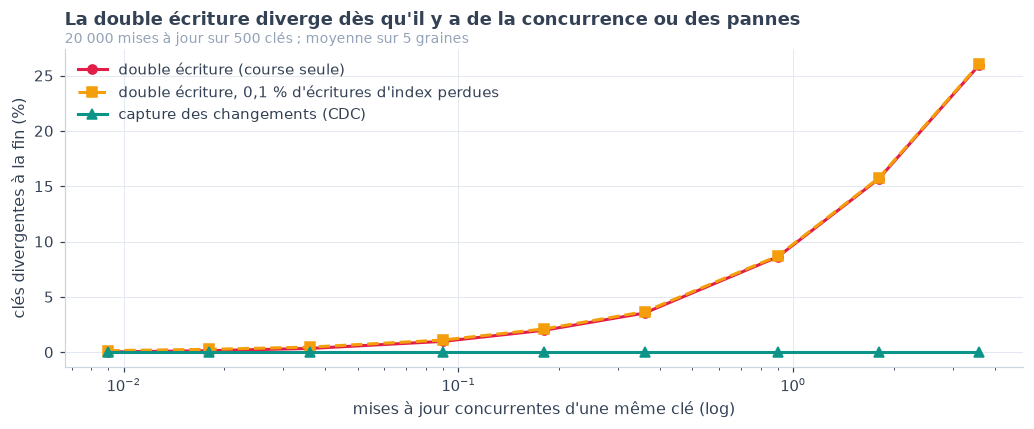

,double écriture,"double écriture + 0,1 % d'échecs",CDC
concurrence par clé,,,
0.009,0.04,0.16,0.0
0.018,0.16,0.28,0.0
0.036,0.36,0.48,0.0
0.090,1.00,1.12,0.0
0.180,2.00,2.12,0.0
0.360,3.56,3.68,0.0
0.900,8.64,8.72,0.0
1.800,15.68,15.76,0.0
3.600,26.00,26.08,0.0


In [5]:
taux = np.array([0.5, 1, 2, 5, 10, 20, 50, 100, 200])
n_keys = 500
conc = taux / n_keys * 9.0
rows = []
for r, c in zip(taux, conc):
    dual = np.mean([st.simulate_dual_writes(20_000, n_keys, r, seed=s)["frac_diverged"] for s in range(5)])
    fail = np.mean([st.simulate_dual_writes(20_000, n_keys, r, fail_prob=0.001, seed=s)["frac_diverged"] for s in range(5)])
    cdc = np.mean([st.simulate_dual_writes(20_000, n_keys, r, mode="cdc", seed=s)["frac_diverged"] for s in range(5)])
    rows.append({"concurrence par clé": c, "double écriture": dual,
                 "double écriture + 0,1 % d'échecs": fail, "CDC": cdc})
R = pd.DataFrame(rows).set_index("concurrence par clé")
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(R.index, R["double écriture"] * 100, "o-", color=ROSE, label="double écriture (course seule)")
ax.plot(R.index, R["double écriture + 0,1 % d'échecs"] * 100, "s--", color=AMBER,
        label="double écriture, 0,1 % d'écritures d'index perdues")
ax.plot(R.index, R["CDC"] * 100, "^-", color=TEAL, label="capture des changements (CDC)")
ax.set_xscale("log")
ax.set_xlabel("mises à jour concurrentes d'une même clé (log)"); ax.set_ylabel("clés divergentes à la fin (%)")
ax.set_title("La double écriture diverge dès qu'il y a de la concurrence ou des pannes")
subtitle(ax, "20 000 mises à jour sur 500 clés ; moyenne sur 5 graines")
ax.legend()
plt.tight_layout(); plt.show()
R.mul(100).round(2)

Quand une clé n'est presque jamais modifiée deux fois en même temps, la course est rare
mais les échecs partiels, eux, laissent des clés divergentes ; dès qu'une clé est
modifiée en moyenne une fois pendant la durée d'une double écriture (concurrence proche
de 1), environ 9 % des clés finissent incohérentes, et plus d'un quart à 3,6. Dans les deux
cas, **aucune erreur n'est remontée**. La situation serait bien meilleure s'il n'y avait
**qu'un seul leader**, la base, et si l'index en était un **suiveur**.

> **À retenir.** La double écriture souffre d'une course (deux systèmes ordonnent
> différemment les mêmes écritures) et d'échecs partiels (une écriture sur deux réussit) ;
> les incohérences qui en résultent sont permanentes et silencieuses.

## 3. La capture des changements (sections *Change Data Capture* et *Implementing change data capture*)

Longtemps, le journal de réplication d'une base a été considéré comme un détail
d'implémentation interne, pas comme une interface publique : on était censé interroger la
base par son modèle de données et son langage de requête. La **capture des changements**
(change data capture, CDC) consiste à observer toutes les écritures validées dans une base
et à les extraire sous une forme réplicable vers d'autres systèmes, idéalement comme un
**flux**, dès leur validation.

La base devient le **leader** dont on capture les changements, et les autres systèmes ses
**suiveurs** (des systèmes de données dérivées). Un courtier à journal est le transport
idéal, puisqu'il préserve l'ordre (pas de réordonnancement comme au cours 1). Ajouter un
système, par exemple l'entrepôt, revient à brancher un consommateur de plus.

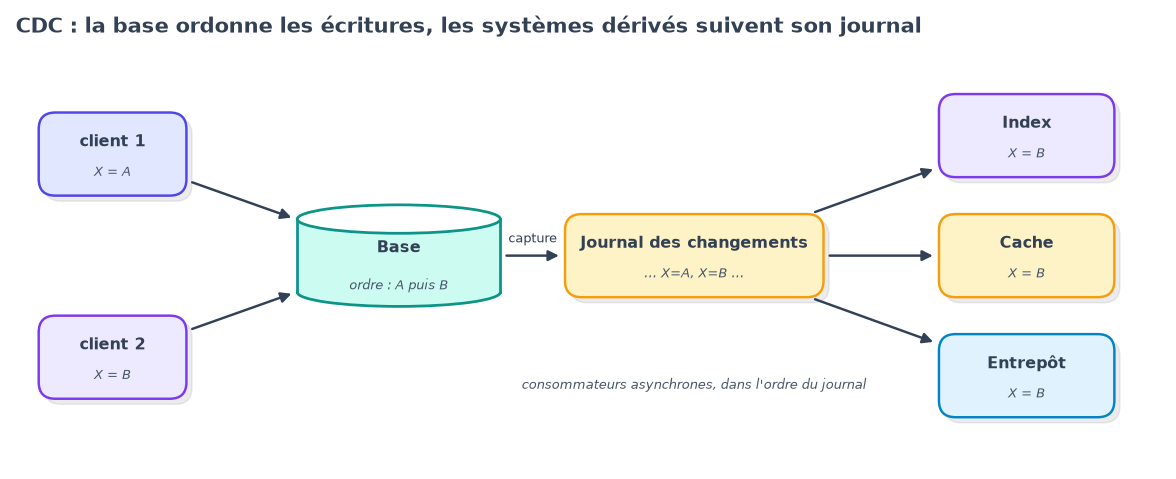

In [6]:
d = Diagram(12.5, 4.4, title="CDC : la base ordonne les écritures, les systèmes dérivés suivent son journal")
d.box("c1", 1.1, 3.4, "client 1", sub="X = A", color=INDIGO, w=1.6)
d.box("c2", 1.1, 1.2, "client 2", sub="X = B", color=VIOLET, w=1.6)
d.box("db", 4.2, 2.3, "Base", sub="ordre : A puis B", color=TEAL, kind="db", w=2.2, h=1.1)
d.box("log", 7.4, 2.3, "Journal des changements", sub="… X=A, X=B …", color=AMBER, w=2.8)
d.box("idx", 11.0, 3.6, "Index", sub="X = B", color=VIOLET, w=1.9)
d.box("cache", 11.0, 2.3, "Cache", sub="X = B", color=AMBER, w=1.9)
d.box("dw", 11.0, 1.0, "Entrepôt", sub="X = B", color=SKY, w=1.9)
d.arrow("c1", "db"); d.arrow("c2", "db")
d.arrow("db", "log", "capture")
for t in ("idx", "cache", "dw"):
    d.arrow("log", t, "")
d.note(7.4, 0.9, "consommateurs asynchrones, dans l'ordre du journal", fontsize=8.5)
d.show()

Implémentons une CDC minimale sur SQLite avec `st.CdcDatabase` : pour chaque table suivie,
trois déclencheurs (après INSERT, UPDATE et DELETE) ajoutent une ligne à une table
`_changelog` dont la clé auto-incrémentée `lsn` joue le rôle de position dans le journal.
Comme les déclencheurs s'exécutent dans la transaction de l'écriture, le journal reflète
exactement l'**ordre de validation**. (Les vrais outils lisent plutôt le journal de
réplication logique de la base : c'est l'objet du lab PostgreSQL du chapitre.)

In [7]:
db = st.CdcDatabase()
db.create_table("produits", "id", ["id", "nom", "text"])
db.execute("INSERT INTO produits VALUES (1, 'Lampe', 'lampe de bureau en laiton')")
db.execute("INSERT INTO produits VALUES (2, 'Chaise', 'chaise en chêne massif')")
db.execute("UPDATE produits SET text = 'lampe de bureau en acier brossé' WHERE id = 1")
db.execute("INSERT INTO produits VALUES (3, 'Table', 'table basse en chêne')")
db.execute("DELETE FROM produits WHERE id = 2")
pd.DataFrame(db.changes()).set_index("lsn")

,table,op,key,row
lsn,,,,
1,produits,insert,1,"{'id': 1, 'nom': 'Lampe', 'text': 'lampe de bu..."
2,produits,insert,2,"{'id': 2, 'nom': 'Chaise', 'text': 'chaise en ..."
3,produits,update,1,"{'id': 1, 'nom': 'Lampe', 'text': 'lampe de bu..."
4,produits,insert,3,"{'id': 3, 'nom': 'Table', 'text': 'table basse..."
5,produits,delete,2,None


Un consommateur lit ce journal à partir de sa position et maintient un index plein texte
(`st.SearchIndex`). Rejouons maintenant la course de la section 2 : deux clients
modifient le même produit « en même temps ». Quel que soit l'ordre que la base choisit,
l'index l'applique à l'identique.

In [8]:
idx = st.SearchIndex()
for ch in db.changes(since=idx.position):
    idx.apply(ch)
print("« chêne » :", idx.search("chêne"), "| « laiton » :", idx.search("laiton"), "| « acier » :", idx.search("acier"))

coherent = 0
for essai in range(200):
    r = np.random.default_rng(essai)
    for _ in range(20):                                   # 20 mises à jour concurrentes du produit 3
        texte = f"table basse version {int(r.integers(0, 1000))}"
        db.execute("UPDATE produits SET text = ? WHERE id = 3", (texte,))
        if r.random() < 0.3:                              # consommateur en retard : il lit par paquets
            for ch in db.changes(since=idx.position, limit=int(r.integers(1, 5))):
                idx.apply(ch)
    for ch in db.changes(since=idx.position):             # rattrapage
        idx.apply(ch)
    texte_db = db.execute("SELECT text FROM produits WHERE id = 3").fetchone()[0]
    coherent += idx.docs[3] == texte_db
print(f"index identique à la base après rattrapage : {coherent} essais sur 200")

« chêne » : [3] | « laiton » : [] | « acier » : [1]
index identique à la base après rattrapage : 200 essais sur 200


L'index est toujours identique à la base **une fois le retard rattrapé**. Pendant le
retard, il est périmé : comme les courtiers, la CDC est en général **asynchrone** (la base
n'attend pas les consommateurs pour valider). C'est un avantage opérationnel (un
consommateur lent ne ralentit pas la base) et un inconvénient : on retrouve tous les
problèmes du retard de réplication (chapitre 5), comme lire une donnée
que l'on vient d'écrire et ne pas la trouver dans l'index.

Côté outils, LinkedIn (Databus), Facebook (Wormhole) et Yahoo! (Sherpa) ont construit leurs propres systèmes ; Bottled Water fait de la CDC pour PostgreSQL en décodant le journal d'écriture anticipée, Maxwell et Debezium pour MySQL en lisant le binlog, Mongoriver pour MongoDB, GoldenGate pour Oracle.

> **À retenir.** La CDC fait de la base le leader et des systèmes dérivés ses suiveurs :
> ils appliquent les écritures dans l'ordre de validation, ce qui supprime la course de la
> double écriture. Le prix est un retard (asynchrone), comme pour toute réplication.

## 4. L'instantané initial (section *Initial snapshot*)

Avec le journal de **tous** les changements depuis la création de la base, on pourrait
reconstruire son état complet en le rejouant. Mais garder tout l'historique demande trop
de place et le rejouer trop de temps : le journal est tronqué. Or construire un nouvel
index exige une copie **complète** de la base ; les seuls changements récents ne
suffisent pas (il manquerait tous les éléments non modifiés récemment). Il faut donc
partir d'un **instantané cohérent**, comme pour ajouter un suiveur à une base répliquée
(chapitre 5), et cet instantané doit correspondre à une **position connue
du journal**, à partir de laquelle appliquer les changements suivants.

Comparons trois façons de construire un nouvel index sur une base de 2 000 produits dont
le journal a été tronqué par la rétention.

In [9]:
base = st.CdcDatabase()
base.create_table("produits", "id", ["id", "text"])
mots = ["chêne", "acier", "laiton", "verre", "noyer", "lin", "cuir", "rotin"]
r = np.random.default_rng(1)
for i in range(2000):
    base.execute("INSERT INTO produits VALUES (?, ?)", (i, " ".join(r.choice(mots, 3))))
for _ in range(3000):
    base.execute("UPDATE produits SET text = ? WHERE id = ?", (" ".join(r.choice(mots, 3)), int(r.integers(0, 2000))))
base.execute("DELETE FROM _changelog WHERE lsn <= 4000")          # rétention : seuls les 1 000 derniers changements restent

def ecritures_concurrentes(n, graine):
    g = np.random.default_rng(graine)
    for _ in range(n):
        base.execute("UPDATE produits SET text = ? WHERE id = ?", (" ".join(g.choice(mots, 3)), int(g.integers(0, 2000))))

def verite():
    return dict(base.execute("SELECT id, text FROM produits").fetchall())

# (a) le journal seul
a = st.SearchIndex()
for ch in base.changes():
    a.apply(ch)
# (b) instantané, puis position lue APRÈS des écritures concurrentes (incohérent)
b = st.SearchIndex()
lignes = base.execute("SELECT id, text FROM produits").fetchall()
ecritures_concurrentes(50, 7)
pos = base.execute("SELECT MAX(lsn) FROM _changelog").fetchone()[0]
for k, t in lignes:
    b.upsert(k, t)
b.position = pos
# (c) instantané cohérent : lignes et position lues dans la même transaction
c = st.SearchIndex()
pos, lignes = base.snapshot("produits")
for k, t in lignes:
    c.upsert(k, t)
c.position = pos
ecritures_concurrentes(50, 8)
# chacun rattrape ensuite le journal depuis sa position
for ix in (a, b, c):
    for ch in base.changes(since=ix.position):
        ix.apply(ch)
v = verite()
res = pd.DataFrame({nom: {"documents indexés": len(ix.docs),
                          "documents faux ou manquants": sum(ix.docs.get(k) != t for k, t in v.items())}
                    for nom, ix in [("(a) journal tronqué seul", a), ("(b) instantané + position tardive", b),
                                    ("(c) instantané cohérent", c)]}).T
res

,documents indexés,documents faux ou manquants
(a) journal tronqué seul,854,1146
(b) instantané + position tardive,2000,49
(c) instantané cohérent,2000,0


Le journal tronqué ne connaît que les produits modifiés récemment (a). Un instantané dont
la position est lue après coup (b) **saute** les écritures survenues entre la lecture des
lignes et la lecture de la position : une petite fraction de documents restent faux, pour
toujours. Seul l'instantané **cohérent** (c), lignes et position lues dans la même
transaction, donne un index exact. Certains outils de CDC intègrent cette étape,
d'autres la laissent à l'opérateur.

> **À retenir.** Un nouveau système dérivé part d'un instantané cohérent **et** de sa
> position exacte dans le journal des changements ; une position approximative produit
> des incohérences définitives.

## 5. La compaction du journal (section *Log compaction*)

Refaire un instantané à chaque nouveau système dérivé est pénible. La **compaction de
journal**, vue pour les moteurs de stockage à journal (chapitre 3), offre une
alternative : périodiquement, en arrière-plan, on cherche les enregistrements de même clé,
on jette les anciens et on ne garde que **la dernière valeur de chaque clé** ; une
valeur spéciale nulle, la **pierre tombale** (tombstone), signale une suppression et fait
disparaître la clé. L'espace occupé dépend alors du **contenu actuel** de la base, non du
nombre d'écritures passées.

La même idée s'applique à un sujet de CDC si chaque événement porte la clé primaire et la
**valeur complète** de la ligne : il suffit de garder le dernier événement de chaque clé.
Kafka le propose (`cleanup.policy=compact`). Simulons 200 000 mises à jour de 2 000
clés, à popularité très inégale (loi de Zipf), avec compaction à chaque segment rempli.

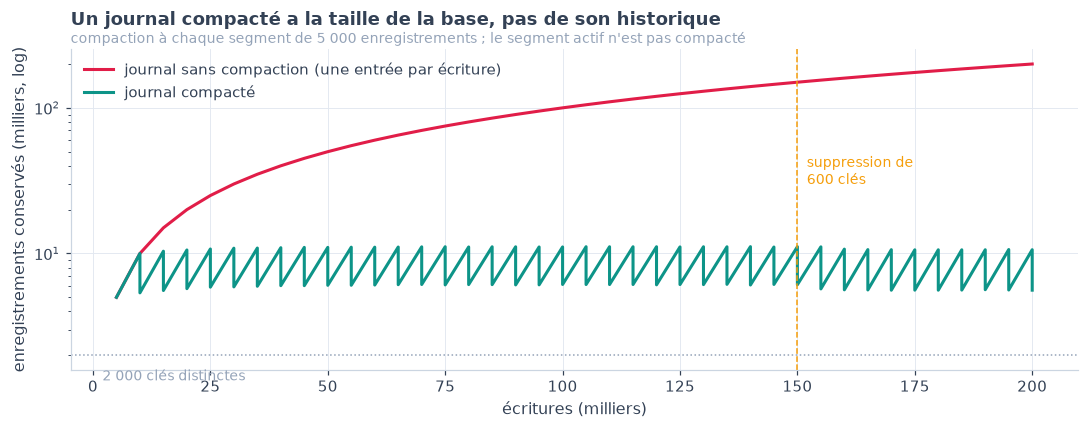

fin : 200600 écritures, 6199 enregistrements conservés


In [10]:
n_cles, n_ecritures, seg = 2000, 200_000, 5000
pop = 1.0 / np.arange(1, n_cles + 1) ** 1.1
pop /= pop.sum()
cles = rng.choice(n_cles, n_ecritures, p=pop)
operations = []                                         # (clé, valeur) ; valeur None = pierre tombale
for i, k in enumerate(cles):
    if i == 150_000:                                    # suppression des 600 clés de numéro >= 1 400
        operations += [(kk, None) for kk in range(1400, n_cles)]
    operations.append((int(k) if i < 150_000 else int(k) % 1400, i))
sujet = st.PartitionedLog(1, segment_size=seg)
brut, compacte = [], []
for j, (k, v) in enumerate(operations):
    sujet.append(k, v, partition=0)
    if (j + 1) % seg == 0:
        brut.append(j + 1); compacte.append(sujet.size(0))       # juste avant la compaction
        sujet.compact(0)
        brut.append(j + 1); compacte.append(sujet.size(0))       # juste après
fig, ax = plt.subplots(figsize=(10, 4))
x = np.array(brut)
ax.plot(x / 1000, x / 1000, color=ROSE, label="journal sans compaction (une entrée par écriture)")
ax.plot(x / 1000, np.array(compacte) / 1000, color=TEAL, label="journal compacté")
ax.set_yscale("log")
ax.axhline(n_cles / 1000, color=GRAY, ls=":", lw=1)
ax.text(2, n_cles / 1000 * 0.8, "2 000 clés distinctes", color=GRAY, fontsize=9, va="top")
ax.axvline(150, color=AMBER, lw=1, ls="--")
ax.text(152, 30, "suppression de\n600 clés", color=AMBER, fontsize=9)
ax.set_xlabel("écritures (milliers)"); ax.set_ylabel("enregistrements conservés (milliers, log)")
ax.set_title("Un journal compacté a la taille de la base, pas de son historique")
subtitle(ax, "compaction à chaque segment de 5 000 enregistrements ; le segment actif n'est pas compacté")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"fin : {len(operations)} écritures, {sujet.size(0)} enregistrements conservés")

Le journal compacté plafonne à « clés vivantes + segment actif » (le segment en cours
d'écriture n'est jamais compacté, d'où les dents de scie), et redescend quand des clés
sont supprimées. Pour reconstruire un système dérivé, il suffit alors de démarrer un
consommateur à l'**offset 0** du sujet compacté et de tout lire : on obtient la dernière
valeur de chaque clé (et parfois quelques valeurs plus anciennes, encore dans le segment
actif), donc une copie complète, **sans nouvel instantané de la base source**. Vérifions
en reconstruisant l'état depuis le sujet compacté.

In [11]:
etat = {}
for rec in sujet.read(0, 0):
    if rec.value is None:
        etat.pop(rec.key, None)
    else:
        etat[rec.key] = rec.value
attendu = {}
for k, v in operations:                                 # l'état de la « base » : on rejoue tout l'historique
    if v is None:
        attendu.pop(k, None)
    else:
        attendu[k] = v
print(f"clés reconstruites : {len(etat)} ; identiques à l'état attendu : {etat == attendu}")

clés reconstruites : 1400 ; identiques à l'état attendu : True


La compaction permet ainsi au courtier de servir de **stockage durable**, et pas seulement
de messagerie transitoire : un sujet compacté *est* une copie de la base, sous forme de
journal.

> **À retenir.** La compaction ne garde que la dernière valeur de chaque clé (et oublie
> les clés supprimées) ; un sujet de CDC compacté permet de reconstruire n'importe quel
> système dérivé en relisant depuis l'offset 0.